# Week 2: Decision trees and random forests

Housing data: `data/house_pricing_ml_exercise.csv`. The workflow covers cleaning, tree regression, forest regression, tree classification, forest classification, comparisons, and feature importance.

Run from the `ml` folder with `numpy`, `pandas`, `matplotlib`, and `scikit-learn` installed. A training subset fits candidate models, a validation subset selects settings, and a final test set measures the selected models.

## 1. Core concepts

- A **decision tree** splits houses into groups using conditions such as living area below a threshold. A leaf is a final group that produces a prediction.
- A **regression tree** chooses splits that reduce price variation, commonly measured by squared error. A **classification tree** chooses splits that make classes purer, using Gini impurity or entropy.
- `max_depth` limits the number of successive splits. `min_samples_leaf` prevents tiny leaves. A very deep tree can memorize training examples and **overfit**.
- A **random forest** averages many trees. Each tree trains on a bootstrap sample and considers a random subset of features at splits. Averaging often reduces the instability of a single tree, at the cost of more computation.
- Feature importance summarizes which inputs the fitted forest used for splits. It does not show a causal effect.

## 2. Raw-data preparation

Missing values, malformed numbers, inconsistent categories, and duplicate properties are corrected. Imputation and encoding remain inside each pipeline, where their values are learned from fitting rows only.

In [1]:
import pandas as pd
raw = pd.read_csv('data/house_pricing_ml_exercise.csv')
print('Original rows:', len(raw))
print('Duplicate properties ignoring ID:',
      raw.duplicated(subset=[c for c in raw.columns if c != 'house_id']).sum())
display(raw.head(3))

Original rows: 1208
Duplicate properties ignoring ID: 8


,house_id,city,neighborhood,property_type,bedrooms,bathrooms,living_area_sqm,lot_size_sqm,year_built,condition,parking_spaces,distance_city_center_km,school_rating_1_10,crime_rate_1_10,has_garden,has_balcony,energy_rating,sale_price_eur,high_price
0,H0001,Frankfurt,Westend,Apartment,3,1,79.2,0,2004,Excellent,1,1.5,6.6,2.6,No,No,D,675000,1
1,H0002,Frankfurt,Gallus,Terraced House,5,2,127.3,514.9,1979,Average,2,4.1,7.4,3.6,No,Yes,D,716000,1
2,H0003,Frankfurt,Bockenheim,Apartment,2,1,45.8 sqm,0,2004,Needs Renovation,0,4.2,8.7,4.3,No,Yes,A+,266000,0


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd

DATA_PATH = Path('data/house_pricing_ml_exercise.csv')
if not DATA_PATH.exists():
    raise FileNotFoundError('Run from the ml folder; data/house_pricing_ml_exercise.csv is required.')

numeric_features = [
    'bedrooms', 'bathrooms', 'living_area_sqm', 'lot_size_sqm', 'year_built',
    'parking_spaces', 'distance_city_center_km', 'school_rating_1_10',
    'crime_rate_1_10', 'has_garden', 'has_balcony',
]
categorical_features = ['city', 'neighborhood', 'property_type', 'condition', 'energy_rating']


def load_housing():
    df = pd.read_csv(DATA_PATH, na_values=['?', 'n/a', 'NA', ''])
    # Remove repeated properties before splitting, so copies cannot appear in both sets.
    df = df.drop_duplicates(subset=[c for c in df.columns if c != 'house_id']).copy()
    for col in numeric_features[:-2]:
        # Handles entries such as "1 baths" and "90m2"; invalid entries become NaN.
        numbers = df[col].astype('string').str.extract(r'(-?\d+(?:\.\d+)?)', expand=False)
        df[col] = pd.to_numeric(numbers, errors='coerce')
    for col in ['has_garden', 'has_balcony']:
        values = df[col].astype('string').str.strip().str.lower()
        df[col] = values.map({'yes': 1, 'y': 1, 'true': 1, '1': 1,
                              'no': 0, 'n': 0, 'false': 0, '0': 0}).astype(float)
    for col in categorical_features:
        clean = df[col].astype('string').str.strip().str.lower()
        df[col] = clean.astype(object).where(clean.notna(), np.nan)
    df['city'] = df['city'].replace({
        'berln': 'berlin', 'colgne': 'cologne', 'koeln': 'cologne',
        'frankfrut': 'frankfurt', 'hambug': 'hamburg',
        'leipzg': 'leipzig', 'münich': 'munich',
    })
    df['property_type'] = df['property_type'].replace({
        'apartmnt': 'apartment', 'detached': 'detached house',
        'detatched house': 'detached house', 'semi detached': 'semi-detached',
        'semi-detatched': 'semi-detached', 'terrace house': 'terraced house',
        'terraced hse': 'terraced house',
    })
    df['condition'] = df['condition'].replace({
        'averge': 'average', 'excelent': 'excellent', 'gud': 'good',
        'needs renovaton': 'needs renovation', 'renovation needed': 'needs renovation',
    })
    df['energy_rating'] = df['energy_rating'].replace({'dd': 'd'})
    df['sale_price_eur'] = pd.to_numeric(df['sale_price_eur'], errors='coerce')
    df['high_price'] = pd.to_numeric(df['high_price'], errors='coerce')
    return df.dropna(subset=['sale_price_eur', 'high_price']).reset_index(drop=True)

housing = load_housing()
print(f'{len(housing)} houses; {housing.high_price.mean():.1%} are high priced')
print('Target matches EUR 500,000 rule:',
      bool(((housing.sale_price_eur >= 500_000).astype(int) == housing.high_price).all()))

1200 houses; 63.4% are high priced
Target matches EUR 500,000 rule: True


In [3]:
print('Rows after cleaning:', len(housing))
print('Missing feature cells after basic cleaning:',
      int(housing[numeric_features + categorical_features].isna().sum().sum()))
print('The model pipelines will impute these from their own training rows.')

Rows after cleaning: 1200
Missing feature cells after basic cleaning: 342
The model pipelines will impute these from their own training rows.


## 3. Features, targets, and splits

Exclude `house_id` from both tasks. Exclude `high_price` when predicting price because it is derived from price. Exclude `sale_price_eur` when predicting `high_price`. Reserve 20% of rows for final testing; use a subset of the remaining rows for validation.

In [3]:
from sklearn.model_selection import train_test_split
all_rows = np.arange(len(housing))
y_price = housing['sale_price_eur']
y_high = housing['high_price'].astype(int)
X = housing[numeric_features + categorical_features]
train_rows, test_rows = train_test_split(
    all_rows, test_size=.20, random_state=42, stratify=y_high
)
fit_rows, val_rows = train_test_split(
    train_rows, test_size=.25, random_state=42, stratify=y_high.iloc[train_rows]
)
X_fit, X_val = X.iloc[fit_rows], X.iloc[val_rows]
X_train, X_test = X.iloc[train_rows], X.iloc[test_rows]
price_fit, price_val = y_price.iloc[fit_rows], y_price.iloc[val_rows]
price_train, price_test = y_price.iloc[train_rows], y_price.iloc[test_rows]
high_fit, high_val = y_high.iloc[fit_rows], y_high.iloc[val_rows]
high_train, high_test = y_high.iloc[train_rows], y_high.iloc[test_rows]
assert {'house_id', 'sale_price_eur', 'high_price'}.isdisjoint(X.columns)
print(f'Fit: {len(fit_rows)} | Validation: {len(val_rows)} | Final test: {len(test_rows)}')

Fit: 720 | Validation: 240 | Final test: 240


In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def make_preprocessor(numeric_columns=numeric_features, categorical_columns=categorical_features):
    return ColumnTransformer([
        ('numbers', Pipeline([
            ('impute', SimpleImputer(strategy='median')),
            ('scale', StandardScaler()),
        ]), numeric_columns),
        ('categories', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('encode', OneHotEncoder(handle_unknown='ignore')),
        ]), categorical_columns),
    ])

## 4. Decision tree regression

Three configurations test the effect of depth and minimum leaf size. Training and validation errors reveal overfitting. Select the configuration with the lowest validation MAE.

In [5]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

tree_reg_configs = {
    'Shallow': {'max_depth': 3, 'min_samples_split': 20, 'min_samples_leaf': 10},
    'Medium': {'max_depth': 7, 'min_samples_split': 10, 'min_samples_leaf': 5},
    'Deep': {'max_depth': None, 'min_samples_split': 2, 'min_samples_leaf': 1},
}

def regression_scores(actual, predicted):
    return {'MAE (€)': mean_absolute_error(actual, predicted),
            'RMSE (€)': np.sqrt(mean_squared_error(actual, predicted)),
            'R²': r2_score(actual, predicted)}

tree_reg_rows = []
for name, params in tree_reg_configs.items():
    model = Pipeline([
        ('prepare', make_preprocessor()),
        ('model', DecisionTreeRegressor(**params, random_state=42)),
    ])
    model.fit(X_fit, price_fit)
    train_scores = regression_scores(price_fit, model.predict(X_fit))
    val_scores = regression_scores(price_val, model.predict(X_val))
    tree_reg_rows.append({
        'Configuration': name, 'Train MAE (€)': train_scores['MAE (€)'],
        'Validation MAE (€)': val_scores['MAE (€)'],
        'Validation RMSE (€)': val_scores['RMSE (€)'],
        'Validation R²': val_scores['R²'],
    })
tree_reg_table = pd.DataFrame(tree_reg_rows).set_index('Configuration')
display(tree_reg_table.round(3))
best_tree_reg = tree_reg_table['Validation MAE (€)'].idxmin()
print('Best validation tree:', best_tree_reg)
print('Deep-tree train/validation MAE gap:',
      f'€{tree_reg_table.loc["Deep", "Validation MAE (€)"] - tree_reg_table.loc["Deep", "Train MAE (€)"]:,.0f}')

,Train MAE (€),Validation MAE (€),Validation RMSE (€),Validation R²
Configuration,,,,
Shallow,176420.291,189879.307,238586.317,0.658
Medium,112256.216,163550.271,223702.299,0.699
Deep,0.000,170833.333,238574.010,0.658


Best validation tree: Medium
Deep-tree train/validation MAE gap: €170,833


The validation table identifies the selected configuration. The deep tree's much smaller training error and larger validation error show overfitting. Feature importance from the refitted tree appears below.

## 5. Random forest regression

Three configurations vary `n_estimators`, `max_depth`, `min_samples_leaf`, and `max_features`. More trees increase computing time and do not automatically correct unsuitable depth or leaf settings.

In [6]:
from sklearn.ensemble import RandomForestRegressor
rf_reg_configs = {
    'Small/limited': {'n_estimators': 60, 'max_depth': 7, 'min_samples_leaf': 5, 'max_features': .7},
    'Medium': {'n_estimators': 100, 'max_depth': 12, 'min_samples_leaf': 2, 'max_features': .8},
    'Large/flexible': {'n_estimators': 150, 'max_depth': None, 'min_samples_leaf': 1, 'max_features': 1.0},
}
rf_reg_rows = []
for name, params in rf_reg_configs.items():
    model = Pipeline([
        ('prepare', make_preprocessor()),
        ('model', RandomForestRegressor(**params, random_state=42, n_jobs=1)),
    ])
    model.fit(X_fit, price_fit)
    train_scores = regression_scores(price_fit, model.predict(X_fit))
    val_scores = regression_scores(price_val, model.predict(X_val))
    rf_reg_rows.append({
        'Configuration': name, 'Train MAE (€)': train_scores['MAE (€)'],
        'Validation MAE (€)': val_scores['MAE (€)'],
        'Validation RMSE (€)': val_scores['RMSE (€)'],
        'Validation R²': val_scores['R²'],
    })
rf_reg_table = pd.DataFrame(rf_reg_rows).set_index('Configuration')
display(rf_reg_table.round(3))
best_rf_reg = rf_reg_table['Validation MAE (€)'].idxmin()
print('Best validation forest:', best_rf_reg)

,Train MAE (€),Validation MAE (€),Validation RMSE (€),Validation R²
Configuration,,,,
Small/limited,110592.369,147152.781,189891.797,0.783
Medium,63776.799,132231.197,174204.253,0.818
Large/flexible,49337.130,128102.694,168646.907,0.829


Best validation forest: Large/flexible


## 6. Final price-model comparison

Refit the selected tree and forest on all training rows. Evaluate them and linear regression on the same held-out test rows. Lower MAE/RMSE and higher R² indicate better test performance.

In [7]:
from sklearn.linear_model import LinearRegression
price_models = {
    'Linear regression': Pipeline([
        ('prepare', make_preprocessor()), ('model', LinearRegression())
    ]),
    'Decision tree': Pipeline([
        ('prepare', make_preprocessor()),
        ('model', DecisionTreeRegressor(**tree_reg_configs[best_tree_reg], random_state=42))
    ]),
    'Random forest': Pipeline([
        ('prepare', make_preprocessor()),
        ('model', RandomForestRegressor(**rf_reg_configs[best_rf_reg], random_state=42, n_jobs=1))
    ]),
}
regression_rows = []
for name, model in price_models.items():
    model.fit(X_train, price_train)
    regression_rows.append({'Model': name, **regression_scores(price_test, model.predict(X_test))})
regression_table = pd.DataFrame(regression_rows).set_index('Model')
display(regression_table.round(3))
print('Lowest final-test MAE:', regression_table['MAE (€)'].idxmin())

,MAE (€),RMSE (€),R²
Model,,,
Linear regression,98088.523,135106.390,0.892
Decision tree,159626.936,228887.276,0.689
Random forest,126744.917,183674.304,0.800


Lowest final-test MAE: Linear regression


## 7. Decision tree classification

The target is `high_price`. Three depth and leaf settings are compared using validation F1. Training F1 near 1 with much lower validation F1 indicates overfitting.

In [8]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)

tree_class_configs = {
    'Shallow': {'max_depth': 3, 'min_samples_split': 20, 'min_samples_leaf': 10},
    'Medium': {'max_depth': 7, 'min_samples_split': 10, 'min_samples_leaf': 5},
    'Deep': {'max_depth': None, 'min_samples_split': 2, 'min_samples_leaf': 1},
}

def classification_scores(actual, predicted):
    return {'Accuracy': accuracy_score(actual, predicted),
            'Precision': precision_score(actual, predicted, zero_division=0),
            'Recall': recall_score(actual, predicted, zero_division=0),
            'F1': f1_score(actual, predicted, zero_division=0)}

tree_class_rows = []
for name, params in tree_class_configs.items():
    model = Pipeline([
        ('prepare', make_preprocessor()),
        ('model', DecisionTreeClassifier(**params, random_state=42)),
    ])
    model.fit(X_fit, high_fit)
    train_scores = classification_scores(high_fit, model.predict(X_fit))
    val_scores = classification_scores(high_val, model.predict(X_val))
    tree_class_rows.append({
        'Configuration': name, 'Train F1': train_scores['F1'],
        'Validation F1': val_scores['F1'],
        'Validation accuracy': val_scores['Accuracy'],
    })
tree_class_table = pd.DataFrame(tree_class_rows).set_index('Configuration')
display(tree_class_table.round(3))
best_tree_class = tree_class_table['Validation F1'].idxmax()
print('Best validation tree:', best_tree_class)

,Train F1,Validation F1,Validation accuracy
Configuration,,,
Shallow,0.897,0.833,0.804
Medium,0.932,0.864,0.838
Deep,1.000,0.873,0.842


Best validation tree: Deep


## 8. Random forest classification

Compare three settings on validation rows, then refit the selected configuration on all training rows.

In [9]:
from sklearn.ensemble import RandomForestClassifier
rf_class_configs = {
    'Small/limited': {'n_estimators': 60, 'max_depth': 7, 'min_samples_leaf': 5, 'max_features': .7},
    'Medium': {'n_estimators': 100, 'max_depth': 12, 'min_samples_leaf': 2, 'max_features': 'sqrt'},
    'Large/flexible': {'n_estimators': 150, 'max_depth': None, 'min_samples_leaf': 1, 'max_features': 'sqrt'},
}
rf_class_rows = []
for name, params in rf_class_configs.items():
    model = Pipeline([
        ('prepare', make_preprocessor()),
        ('model', RandomForestClassifier(**params, random_state=42, n_jobs=1)),
    ])
    model.fit(X_fit, high_fit)
    val_scores = classification_scores(high_val, model.predict(X_val))
    rf_class_rows.append({'Configuration': name, **val_scores})
rf_class_table = pd.DataFrame(rf_class_rows).set_index('Configuration')
display(rf_class_table.round(3))
best_rf_class = rf_class_table['F1'].idxmax()
print('Best validation forest:', best_rf_class)

,Accuracy,Precision,Recall,F1
Configuration,,,,
Small/limited,0.846,0.902,0.849,0.875
Medium,0.854,0.921,0.842,0.880
Large/flexible,0.854,0.927,0.836,0.879


Best validation forest: Medium


## 9. Final classification comparison

Evaluate logistic regression, the selected decision tree, and the selected random forest on the same test rows. The confusion matrices display the tree and forest error counts.

In [10]:
from sklearn.linear_model import LogisticRegression
class_models = {
    'Logistic regression': Pipeline([
        ('prepare', make_preprocessor()),
        ('model', LogisticRegression(max_iter=2000))
    ]),
    'Decision tree': Pipeline([
        ('prepare', make_preprocessor()),
        ('model', DecisionTreeClassifier(**tree_class_configs[best_tree_class], random_state=42))
    ]),
    'Random forest': Pipeline([
        ('prepare', make_preprocessor()),
        ('model', RandomForestClassifier(**rf_class_configs[best_rf_class], random_state=42, n_jobs=1))
    ]),
}
classification_rows = []
for name, model in class_models.items():
    model.fit(X_train, high_train)
    classification_rows.append({'Model': name,
        **classification_scores(high_test, model.predict(X_test))})
classification_table = pd.DataFrame(classification_rows).set_index('Model')
display(classification_table.round(3))
print('Highest final-test F1:', classification_table['F1'].idxmax())
for name in ['Decision tree', 'Random forest']:
    cm = confusion_matrix(high_test, class_models[name].predict(X_test), labels=[0, 1])
    print(name, 'confusion matrix:')
    display(pd.DataFrame(cm,
        index=['Actually low (0)', 'Actually high (1)'],
        columns=['Predicted low (0)', 'Predicted high (1)']))

,Accuracy,Precision,Recall,F1
Model,,,,
Logistic regression,0.933,0.947,0.947,0.947
Decision tree,0.867,0.895,0.895,0.895
Random forest,0.900,0.927,0.914,0.921


Highest final-test F1: Logistic regression
Decision tree confusion matrix:


,Predicted low (0),Predicted high (1)
Actually low (0),72,16
Actually high (1),16,136


Random forest confusion matrix:


,Predicted low (0),Predicted high (1)
Actually low (0),77,11
Actually high (1),13,139


## 10. Forest feature importance

Impurity-based importance is calculated for each encoded input. The tables and charts show the top 10 for price regression and high-price classification. City and neighborhood values appear as separate one-hot categories. Importance can be divided across correlated inputs and does not establish causation.

Regression forest top 10:


,feature,importance
0,numbers__living_area_sqm,0.453
1,categories__city_munich,0.165
2,categories__property_type_apartment,0.125
3,categories__city_leipzig,0.030
4,numbers__distance_city_center_km,0.027
5,numbers__lot_size_sqm,0.023
6,numbers__year_built,0.020
7,numbers__school_rating_1_10,0.018
8,numbers__crime_rate_1_10,0.015
9,categories__neighborhood_maxvorstadt,0.013


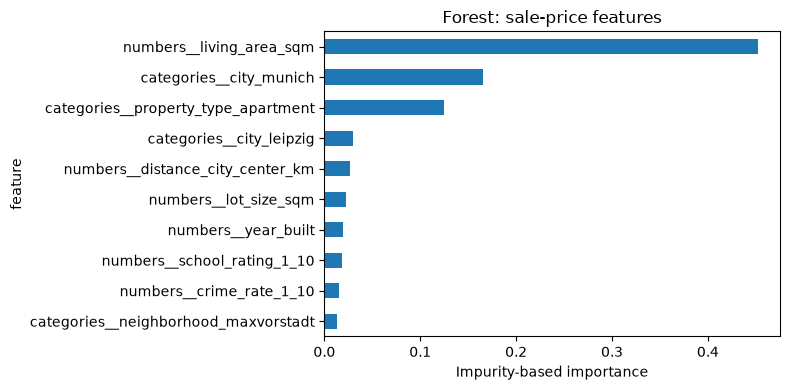

Classification forest top 10:


,feature,importance
0,numbers__living_area_sqm,0.194
1,categories__property_type_apartment,0.168
2,numbers__lot_size_sqm,0.119
3,numbers__bedrooms,0.061
4,numbers__parking_spaces,0.043
5,categories__city_munich,0.040
6,numbers__has_garden,0.030
7,numbers__distance_city_center_km,0.029
8,categories__property_type_detached house,0.029
9,numbers__bathrooms,0.029


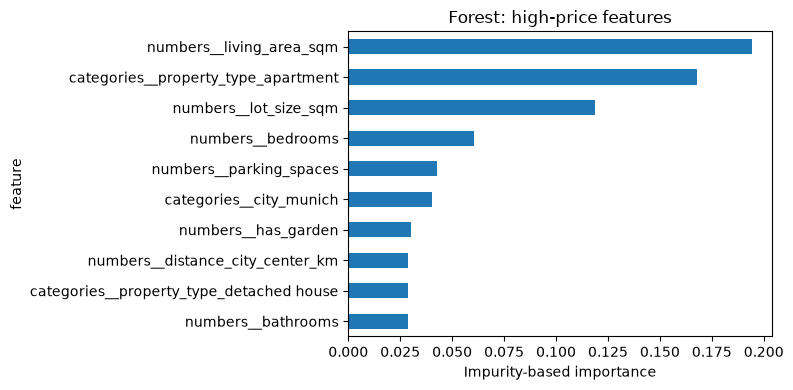

In [11]:
import matplotlib.pyplot as plt

def plot_forest_importance(pipeline, title):
    names = pipeline.named_steps['prepare'].get_feature_names_out()
    values = pipeline.named_steps['model'].feature_importances_
    importance = pd.DataFrame({'feature': names, 'importance': values})
    top = importance.nlargest(10, 'importance').sort_values('importance')
    display(top.sort_values('importance', ascending=False).reset_index(drop=True).round(3))
    ax = top.plot.barh(x='feature', y='importance', legend=False, figsize=(8, 4))
    ax.set_title(title)
    ax.set_xlabel('Impurity-based importance')
    plt.tight_layout()
    plt.show()
    return importance

print('Regression forest top 10:')
reg_importance = plot_forest_importance(price_models['Random forest'], 'Forest: sale-price features')
print('Classification forest top 10:')
class_importance = plot_forest_importance(class_models['Random forest'], 'Forest: high-price features')

In [13]:
# Show the selected tree's most important encoded variables too.
tree_names = price_models['Decision tree'].named_steps['prepare'].get_feature_names_out()
tree_values = price_models['Decision tree'].named_steps['model'].feature_importances_
display(pd.DataFrame({'feature': tree_names, 'importance': tree_values})
        .nlargest(10, 'importance').round(3).reset_index(drop=True))

,feature,importance
0,numbers__living_area_sqm,0.558
1,categories__city_munich,0.200
2,categories__property_type_apartment,0.075
3,categories__city_leipzig,0.037
4,categories__neighborhood_maxvorstadt,0.019
5,numbers__lot_size_sqm,0.017
6,categories__city_cologne,0.015
7,numbers__year_built,0.013
8,categories__neighborhood_bogenhausen,0.013
9,numbers__distance_city_center_km,0.012


## 11. Findings

- A deep tree can overfit by creating leaves for a few training examples, including noise. The deep regression tree here had zero training MAE but about **€171,000 validation MAE**.
- A random forest reduces single-tree instability by averaging trees trained on different bootstrap samples and feature subsets. More trees require additional computation and memory, and the ensemble is harder to interpret.
- **Price prediction:** Linear regression had the lowest final-test MAE, about **€98,000**, followed by the forest at about **€127,000** and the tree at about **€160,000**.
- **High-price classification:** Logistic regression had the highest final-test F1, about **0.95**, followed by the forest at about **0.92** and the tree at about **0.90**. The relevant error cost determines whether F1 is the right selection metric.
- Living area, location, and property type rank highly in the forest tables. Their importance is plausible for housing prices but does not establish causation.
- A linear or logistic model is suitable when its performance is adequate and simpler interpretation, faster training, or clearer explanations are useful.

The forest outperformed the single tree on both final tasks. The results come from one data split; another split may produce different rankings.